<a href="https://colab.research.google.com/github/Sleeppyheadd/Data-Warehouse-and-Data-Mining/blob/main/%E0%B8%AA%E0%B8%B3%E0%B9%80%E0%B8%99%E0%B8%B2%E0%B8%82%E0%B8%AD%E0%B8%87_%E0%B9%81%E0%B8%9A%E0%B8%9A%E0%B8%9D%E0%B8%B6%E0%B8%81%E0%B8%AB%E0%B8%B1%E0%B8%94_IQR_Anomaly_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# แบบฝึกหัด IQR : Anomaly Detection

IQR = Q3 − Q1 · รั้วล่าง = Q1 − k·IQR · รั้วบน = Q3 + k·IQR · k = 1.5 (outlier) หรือ 3 (extreme outlier)


In [4]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt

## ข้อ 1 · คำนวณ IQR และรั้ว (20 คะแนน)

ปริมาณน้ำที่บ้านหลังหนึ่งใช้ต่อวัน 15 วัน

1. ใช้ `np.percentile` หา Q1, Q3, IQR และรั้วล่าง/รั้วบน (k = 1.5)
2. แสดงค่าที่อยู่นอกรั้ว

In [50]:
water = np.array([182, 175, 190, 168, 185, 178, 420, 181, 172, 188, 176, 95, 183, 179, 186], float)  # ลิตร/วัน 15 วัน
# TODO 1.1–1.2
Q1 =np.percentile(water,25)
Q3 =np.percentile(water,75)
iqr=Q3-Q1
lo=Q1-1.5*iqr
hi=Q3+1.5*iqr
mask=(water<lo)|(water>hi)

print(f"Lower: {lo}")
print(f"Upper: {hi}")
print(water[mask])
# TODO 1.1–1.2



Lower: 160.5
Upper: 200.5
[420.  95.]


## ข้อ 2 · เขียนฟังก์ชัน `iqr_outliers` (20 คะแนน)

1. เขียนฟังก์ชันรับ `x` และ `k=1.5` คืนค่า `(mask, lo, hi)` โดย `mask` เป็น boolean array ว่าค่าใดอยู่นอกรั้ว
2. ใช้กับยอดขาย 18 วัน ที่ k = 1.5 และ k = 3 · ค่าใดเป็น outlier ทั่วไป ค่าใดเป็น extreme outlier
3. ทดสอบด้วย `assert` อย่างน้อย 2 กรณี เช่น ข้อมูลไม่มี outlier ต้องได้ mask เป็น False ทั้งหมด

In [15]:
def iqr_outliers(x, k=1.5):
    x=np.array(x,float)
    Q1,Q3=np.percentile(x,[25,75])
    iqr=Q3-Q1
    lo=Q1-k*iqr
    hi=Q3+k*iqr
    mask=(x<lo)|(x>hi)
    return mask,lo,hi
    pass

sales = np.array([52, 48, 55, 61, 47, 50, 53, 49, 58, 51, 120, 54, 46, 79, 50, 57, 30, 52], float)  # ยอดขาย (พันบาท) 18 วัน

# TODO 2.2
for k in [1.5,3]:
  mask,lo,hi=iqr_outliers(sales,k)
  print(f'k={k} mask ={mask.all()} lo={lo} hi={hi}')

# TODO 2.3 assert
assert iqr_outliers([10,11,12,13,14,15,16,17,18,19,100])[0].tolist()==[False]*10+[True]
assert not iqr_outliers([10,11,12,13,14,15,16,17,18,19])[0].any()
print ('ผ่านทุก assert')

k=1.5 mask =False lo=38.375 hi=67.375
k=3 mask =False lo=27.5 hi=78.25
ผ่านทุก assert


## ข้อ 3 · Boxplot กับรั้ว IQR (20 คะแนน)

1. วาด boxplot ของ `sales` ด้วย `plt.boxplot(sales, whis=1.5)` แล้วเก็บผลที่ return ไว้ในตัวแปร
2. วาดเส้นแนวนอนที่รั้วล่างและรั้วบนจากข้อ 2 ทับลงบนกราฟ
3. ดึงค่าปลายหนวด (`['whiskers']`) และจุด flier (`['fliers']`) ออกมา เทียบกับผลของ `iqr_outliers`

**คำถาม:** ปลายหนวดอยู่ที่รั้วพอดีหรือไม่ ถ้าไม่ อยู่ที่ไหน

ปลายหนวดล่าง: 46.0
ปลายหนวดบน: 61.0
จุด Fliers (Outliers): [ 30. 120.  79.]


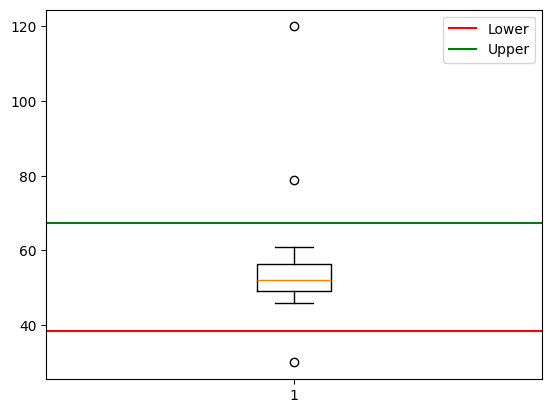

In [33]:
# TODO ข้อ 3

bp=plt.boxplot(sales,whis=1.5)
plt.axhline(y=iqr_outliers(sales)[1],color='r',label="Lower")
plt.axhline(y=iqr_outliers(sales)[2],color='g',label="Upper")
plt.legend()

lo =bp['whiskers'][0].get_ydata()[1]
hi =bp['whiskers'][1].get_ydata()[1]
fliers=bp['fliers'][0].get_data()[1]

print(f"ปลายหนวดล่าง: {lo}")
print(f"ปลายหนวดบน: {hi}")
print(f"จุด Fliers (Outliers): {fliers}")

plt.show()
#

## ข้อ 4 · IQR รายกลุ่ม (contextual anomaly) (20 คะแนน)

ค่าจ้างรายเดือน (พันบาท) ของพนักงาน 3 อาชีพ อาชีพละ 8 คน

1. ใช้ `iqr_outliers` กับค่าจ้างทั้ง 24 คนรวมกัน พบ outlier กี่คน
2. ใช้ `groupby('occupation')` คำนวณ IQR แยกแต่ละอาชีพ (ใช้ `.transform` ได้) พบ outlier คนใด
3. ทำตาราง Q1, Q3, IQR, รั้วล่าง, รั้วบน ของแต่ละอาชีพ
4. อธิบายว่าทำไมผลรวมกับผลรายกลุ่มต่างกัน

In [58]:
wage = pd.DataFrame({
    'occupation': ['cleaner']*8 + ['clerk']*8 + ['engineer']*8,
    'wage_k': [12,13,12,14,13,12,15,35,  18,20,19,22,21,20,23,9,  60,65,58,70,62,66,64,61]})

# TODO 4.1
def iqr_outliers(x, k=1.5):
  Q1=np.percentile(x,25)
  Q3=np.percentile(x,75)
  iqr=Q3-Q1
  lo=Q1-k*iqr
  hi=Q3+k*iqr
  mask=(x<lo)|(x>hi)
  return mask,lo,hi
#1.ใช้ iqr_outliers กับค่าจ้างทั้ง 24 คนรวมกัน พบ outlier กี่คน
global_outliers=iqr_outliers(wage['wage_k'])
print ("ผลรวม ทั้ง 24 คน",global_outliers[0].sum())
#2.ใช้ groupby('occupation') คำนวณ IQR แยกแต่ละอาชีพ (ใช้ .transform ได้) พบ outlier คนใด
group_outlier_mask = wage.groupby('occupation')['wage_k'].transform(lambda x :iqr_outliers (x)[0])
group_outlier_mask = wage[group_outlier_mask]
print("ผลรายกลุ่ม:")
print(group_outlier_mask)
#3.ทำตาราง Q1, Q3, IQR, รั้วล่าง, รั้วบน ของแต่ละอาชีพ
def get_iqr_stats(s, k=1.5):
    Q1 = np.percentile(s, 25) # หรือใช้ s.quantile(0.25)
    Q3 = np.percentile(s, 75) # หรือใช้ s.quantile(0.75)
    iqr = Q3 - Q1
    lo = Q1 - k * iqr
    hi = Q3 + k * iqr
    return pd.Series({
        'Q1': Q1,
        'Q3': Q3,
        'IQR': iqr,
        'รั้วล่าง (Lower)': lo,
        'รั้วบน (Upper)': hi
    })

summary_table = wage.groupby('occupation')['wage_k'].apply(get_iqr_stats).unstack()
print("\nตารางสรุปค่าทางสถิติแยกตามอาชีพ:")
print(summary_table)

ผลรวม ทั้ง 24 คน 0
ผลรายกลุ่ม:
   occupation  wage_k
7     cleaner      35
15      clerk       9

ตารางสรุปค่าทางสถิติแยกตามอาชีพ:
               Q1     Q3   IQR  รั้วล่าง (Lower)  รั้วบน (Upper)
occupation                                                      
cleaner     12.00  14.25  2.25             8.625          17.625
clerk       18.75  21.25  2.50            15.000          25.000
engineer    60.75  65.25  4.50            54.000          72.000


# 4.4 อธิบายว่าทำไมผลรวมกับผลรายกลุ่มต่างกัน
**เมื่อคิดรวมทั้งหมด:** กลุ่มที่ได้เงินเดือนน้อยมีจำนวนเยอะกว่า จึงดึงค่ารั่วบนให้ต่ำลง ทั้งแผนกถูกมองว่าเป็น Outlier ทั้งที่เป็นเงินเดือนปกติและบดบังค่าที่ผิกปกติจริงในกลุ่มเงินเดือนน้อย

**เมื่อคิดรายกลุ่ม :** เป็นการเทียบข้อมูลในอาชีพเดียวกัน ทำให้จับความผิดปกติได้แม่นขึ้น เช่น Cleaner ที่ได้ 3500 สู.ฅกว่าคนอื่นและ  Clerk ได้ 9000 น้อยกว่าคนอื่น